# Test and Control: What Happens When Medicaid Covers, Drops and Restores Obesity Drugs

**Question 1 (a natural experiment):** North Carolina Medicaid began covering
GLP-1 drugs for weight management on 1 August 2024, stopped on 1 October 2025
during a state budget stalemate, and restarted on 12 December 2025. California,
Pennsylvania, New Hampshire and South Carolina ended similar coverage around
January 2026. How much use does coverage create, how much disappears when it
stops, and does it come back?

**Question 2 (designing a pilot):** a brand team wants to test a new programme
in some states before rolling it out. How many test states does it need, how
long must the test run, and which analysis gives a trustworthy answer?

**Data:** Medicaid State Drug Utilization Data (SDUD), every state, 2021 Q1 to
2026 Q1: prescriptions and reimbursement for each GLP-1 product, plus total
prescriptions for all drugs.

**Methods:** synthetic control, difference-in-differences (DiD), an event
study with two-way fixed effects, placebo (permutation) tests, and a power
simulation built on real state-level noise.

**Terms:**
- **Test and control:** compare places that got a change (test) with similar
  places that did not (control). The control shows what would have happened
  anyway, the *counterfactual*.
- **Natural experiment:** a change made for reasons unrelated to the outcome
  (here, a budget dispute), which can be analysed like a planned test.
- **Synthetic control:** a weighted blend of control states built to track
  the test state before the change; its path afterwards is the counterfactual.
- **DiD:** the change in the test state minus the change in the controls over
  the same period.
- **AOM:** anti-obesity medicines (Wegovy, Zepbound, Saxenda). **DM GLP-1:** the
  same drug class labelled for type 2 diabetes (Ozempic, Mounjaro and others).

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
HERE = Path.cwd() if Path.cwd().name.startswith("07-") else Path("07-test-and-control-experiments")
sys.path.insert(0, str(HERE.parent))
sys.path.insert(0, str(HERE))
from common import style  # noqa: E402
import panel  # noqa: E402

style.apply()
RAW, FIG, TAB = HERE / "data" / "raw", HERE / "outputs" / "figures", HERE / "outputs" / "tables"
TAB.mkdir(parents=True, exist_ok=True)
SRC = "CMS Medicaid State Drug Utilization Data, 2021 Q1 to 2026 Q1"
Q = lambda s: pd.Period(s, "Q")  # noqa: E731

p = panel.load(RAW)
p = p[p["state"] != "XX"]  # XX is the national total row
A, D = panel.wide(p, "aom"), panel.wide(p, "dm")
RX = panel.wide(p, "rx_AOM")
SPEND = panel.wide(p, "spend_AOM")
ALL = panel.wide(p, "all_rx")
print(f"{p['state'].nunique()} states and territories, {A.index.min()} to {A.index.max()}")

52 states and territories, 2021Q1 to 2026Q1


## 1. North Carolina's on, off, on

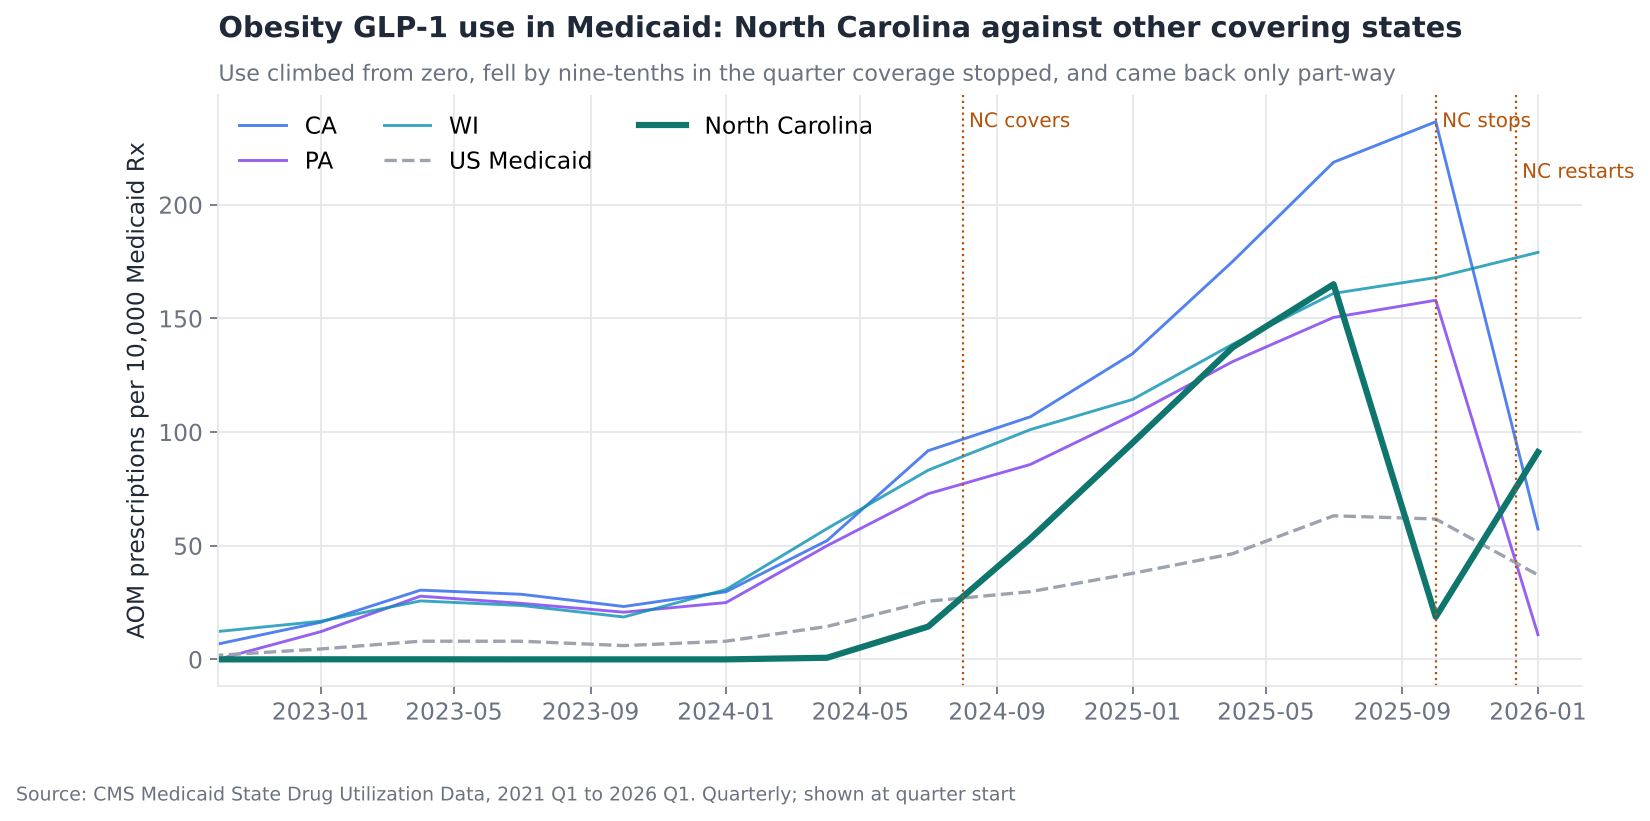

In [2]:
nat = (p.groupby("period")[["rx_AOM", "all_rx"]].sum().pipe(lambda x: x["rx_AOM"] / x["all_rx"] * 1e4))
fig, ax = plt.subplots(figsize=(11, 4.8))
for st, col, lw in [("CA", style.PALETTE[1], 1.3), ("PA", style.PALETTE[3], 1.3), ("WI", style.PALETTE[5], 1.3)]:
    ax.plot(A.index.to_timestamp(), A[st], color=col, lw=lw, alpha=0.8, label=st)
ax.plot(nat.index.to_timestamp(), nat, color=style.NEUTRAL, lw=1.5, ls="--", label="US Medicaid")
ax.plot(A.index.to_timestamp(), A["NC"], color=style.ACCENT, lw=2.8, label="North Carolina")
for when, lab, h in [("2024-08-01", "NC covers", 0.97), ("2025-10-01", "NC stops", 0.97), ("2025-12-12", "NC restarts", 0.88)]:
    ax.axvline(pd.Timestamp(when), color=style.ACCENT_2, lw=1, ls=":")
    ax.text(pd.Timestamp(when), ax.get_ylim()[1] * h, f" {lab}", color=style.ACCENT_2, fontsize=9, va="top")
ax.set_ylabel("AOM prescriptions per 10,000 Medicaid Rx")
ax.set_xlim(pd.Timestamp("2022-10-01"), A.index.max().to_timestamp() + pd.Timedelta(days=40))
ax.set_title("Obesity GLP-1 use in Medicaid: North Carolina against other covering states")
style.subtitle(ax, "Use climbed from zero, fell by nine-tenths in the quarter coverage stopped, and came back only part-way")
ax.legend(loc="upper left", ncol=3)
style.source(fig, SRC + ". Quarterly; shown at quarter start")
style.save(fig, FIG / "01_nc_on_off_on.png")

In [3]:
nc = pd.DataFrame({"AOM per 10k Rx": A["NC"], "AOM prescriptions": RX["NC"], "AOM reimbursed ($M)": SPEND["NC"] / 1e6,
                   "DM GLP-1 per 10k Rx": D["NC"]}).loc[Q("2024Q2"):]
spend_on = float(SPEND.loc[Q("2024Q3"):Q("2025Q3"), "NC"].sum())
print(f"NC reimbursed ${spend_on / 1e6:,.0f}M for obesity GLP-1s in the five covered quarters (before rebates)")
nc.round(1)

NC reimbursed $335M for obesity GLP-1s in the five covered quarters (before rebates)


,AOM per 10k Rx,AOM prescriptions,AOM reimbursed ($M),DM GLP-1 per 10k Rx
period,,,,
2024Q2,0.7,341.0,0.4,95.9
2024Q3,14.4,7229.0,9.4,103.1
2024Q4,53.2,28035.0,37.0,100.6
2025Q1,95.3,51998.0,68.5,108.3
2025Q2,137.2,75137.0,99.2,116.0
2025Q3,165.1,90809.0,121.3,120.5
2025Q4,18.7,10370.0,12.9,121.1
2026Q1,91.2,50509.0,64.5,123.8


Reimbursement here is the gross amount paid to pharmacies. Medicaid receives
large statutory and supplemental rebates afterwards, so the net cost to the
state is lower; but it is the gross figure that hits the budget first.

## 2. How much use disappears when coverage stops?

For each state that dropped coverage, build a synthetic control from states
that kept stable coverage through 2026 Q1, and compare.

The synthetic control is fitted on log rates with the pre-period mean removed
(a "demeaned" synthetic control). That lets a state with higher use than any
donor, such as California, still be matched on its *growth path*.

In [4]:
DONORS = ["MA", "WI", "DE", "MI", "MN", "KS", "MS", "RI", "VA"]
EVENTS = {"NC": "2025Q4", "CA": "2026Q1", "PA": "2026Q1", "NH": "2026Q1"}
PRE_Q = {"NC": 4, "CA": 8, "PA": 8, "NH": 8}


def synth(series: pd.Series, donors: pd.DataFrame, event: pd.Period, n_pre: int):
    """Demeaned synthetic control on logs. Returns (counterfactual series, weights, pre-period RMSPE in logs)."""
    pre = series.index[(series.index < event)][-n_pre:]
    y, Y = np.log(series.clip(lower=0.5)), np.log(donors.clip(lower=0.5))
    y_c, Y_c = y.loc[pre] - y.loc[pre].mean(), Y.loc[pre] - Y.loc[pre].mean()
    w = panel.synth_weights(y_c.to_numpy(), Y_c.to_numpy())
    cf = np.exp(y.loc[pre].mean() + (Y - Y.loc[pre].mean()) @ w)
    rmspe = float(np.sqrt(np.mean((y_c - Y_c @ w) ** 2)))
    return cf, w, rmspe


rows, cfs = [], {}
for st, ev in EVENTS.items():
    ev = Q(ev)
    cf, w, rmspe = synth(A[st], A[DONORS], ev, PRE_Q[st])
    cfs[st] = cf
    did_cf = A.loc[ev - 1, st] * np.exp(np.log(A.loc[ev, DONORS] / A.loc[ev - 1, DONORS]).mean())
    rows.append({"state": st, "coverage ended": str(ev), "rate before": A.loc[ev - 1, st], "rate after": A.loc[ev, st],
                 "synthetic counterfactual": cf.loc[ev], "DiD counterfactual": did_cf,
                 "drop vs synthetic": A.loc[ev, st] / cf.loc[ev] - 1, "drop vs DiD": A.loc[ev, st] / did_cf - 1,
                 "pre-fit error (log RMSPE)": rmspe,
                 "lost prescriptions in quarter": (cf.loc[ev] - A.loc[ev, st]) * ALL.loc[ev, st] / 1e4,
                 "top donors": ", ".join(f"{d} {x:.0%}" for d, x in sorted(zip(DONORS, w), key=lambda t: -t[1])[:3] if x > 0.05)})
removal = pd.DataFrame(rows)
removal.to_csv(TAB / "coverage_removal_effects.csv", index=False)
removal.round(3)

,state,coverage ended,rate before,rate after,synthetic counterfactual,DiD counterfactual,drop vs synthetic,drop vs DiD,pre-fit error (log RMSPE),lost prescriptions in quarter,top donors
0,NC,2025Q4,165.055,18.691,149.954,170.974,-0.875,-0.891,0.196,72827.981,"KS 54%, MS 46%"
1,CA,2026Q1,236.525,57.353,232.138,223.740,-0.753,-0.744,0.058,386770.827,"KS 56%, MS 38%, MA 6%"
2,PA,2026Q1,158.005,10.880,150.742,149.464,-0.928,-0.927,0.006,74738.836,"KS 36%, RI 26%, DE 21%"
3,NH,2026Q1,109.282,15.873,112.341,103.375,-0.859,-0.846,0.046,3798.393,"KS 48%, MA 32%, WI 12%"


Across four states, use fell by 75 to 93% against what was expected in the
quarter coverage ended. (South Carolina also ended coverage, but its volumes
are too small for a stable synthetic control, so it is left out.) The two methods (synthetic control and DiD) agree
within a few points. What remains, the "retained share", is use for the
indications Medicaid still covers with prior authorisation: Wegovy for
cardiovascular risk reduction and MASH, Zepbound for obstructive sleep apnoea.

### Is the drop real? A placebo test

Pretend each donor state lost coverage in 2026 Q1, run the same method, and
see how large a "drop" appears by chance. If real effects are far outside the
placebo spread, they are not noise. The p-value is the share of placebo
effects at least as large as the real one (a permutation test).

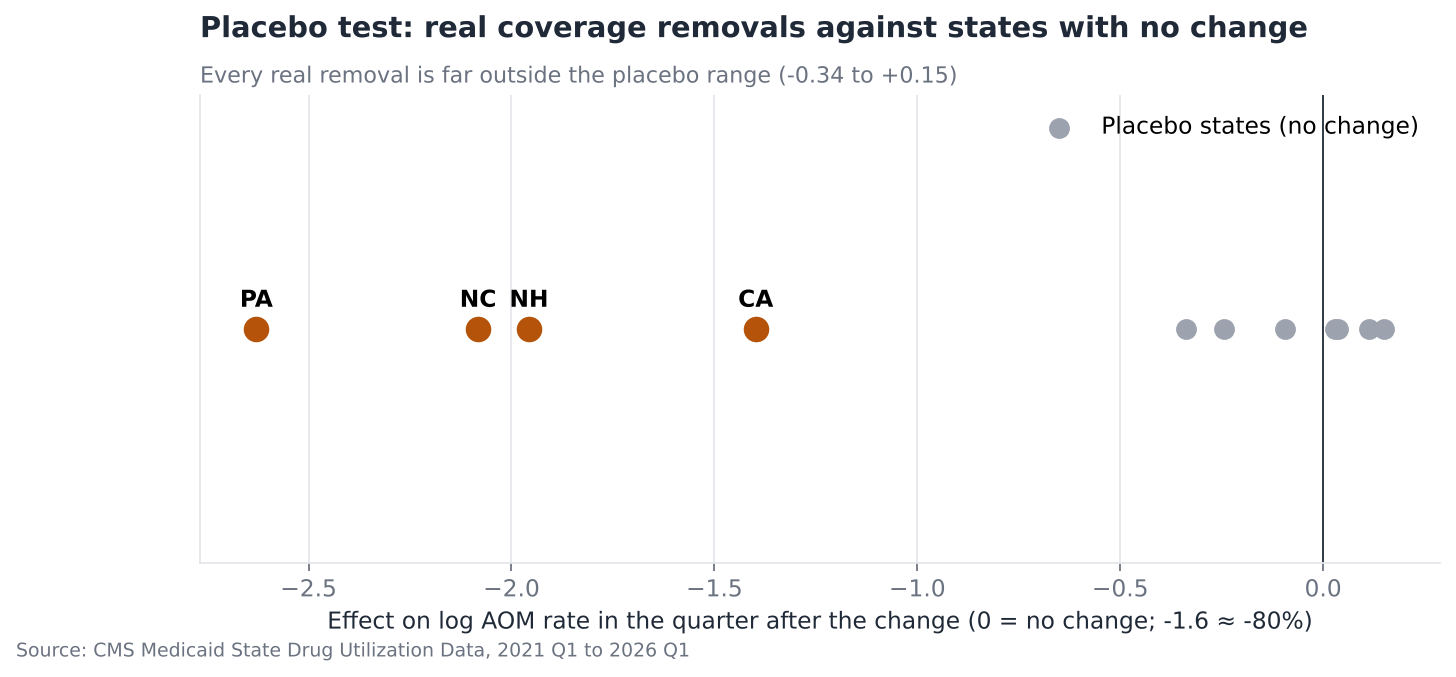

,state,effect,permutation p-value
0,NC,-2.082,0.125
1,CA,-1.398,0.125
2,PA,-2.629,0.125
3,NH,-1.957,0.125


In [5]:
plac = []
for st in DONORS:
    others = [d for d in DONORS if d != st]
    cf, _, rmspe = synth(A[st], A[others], Q("2026Q1"), 8)
    plac.append({"state": st, "effect": float(np.log(A.loc[Q("2026Q1"), st] / cf.loc[Q("2026Q1")])), "pre_rmspe": rmspe})
plac = pd.DataFrame(plac)
# Placebos are only informative where the method can fit the state's past; drop poor fits (Abadie's rule of thumb).
plac = plac[plac["pre_rmspe"] <= 0.2]
real = removal.assign(effect=np.log(removal["rate after"] / removal["synthetic counterfactual"]))
real["permutation p-value"] = [(np.sum(np.abs(plac["effect"]) >= abs(e)) + 1) / (len(plac) + 1) for e in real["effect"]]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(plac["effect"], np.zeros(len(plac)), s=70, color=style.NEUTRAL, label="Placebo states (no change)", zorder=3)
for _, r in real.iterrows():
    ax.scatter(r["effect"], 0, s=110, color=style.ACCENT_2, zorder=4)
    ax.annotate(r["state"], (r["effect"], 0), xytext=(0, 10), textcoords="offset points", ha="center", fontweight="bold")
ax.axvline(0, color=style.INK, lw=0.8)
ax.set_yticks([])
ax.set_xlabel("Effect on log AOM rate in the quarter after the change (0 = no change; -1.6 ≈ -80%)")
ax.set_title("Placebo test: real coverage removals against states with no change")
style.subtitle(ax, f"Every real removal is far outside the placebo range ({plac['effect'].min():+.2f} to {plac['effect'].max():+.2f})")
ax.legend(loc="upper right")
style.source(fig, SRC)
style.save(fig, FIG / "02_placebo_test.png")
real[["state", "effect", "permutation p-value"]].round(3)

Placebo states the method cannot fit well beforehand (pre-period error above
0.2 log points) are left out, as is standard. With seven placebos the smallest
possible p-value is 1/8 = 0.125, so this test cannot reach the conventional
0.05 however large the effect. The size of the gap is the stronger evidence:
the real drops are 1.4 to 2.6 log points, and no placebo moves more than about
a third of a point.

### Synthetic control paths

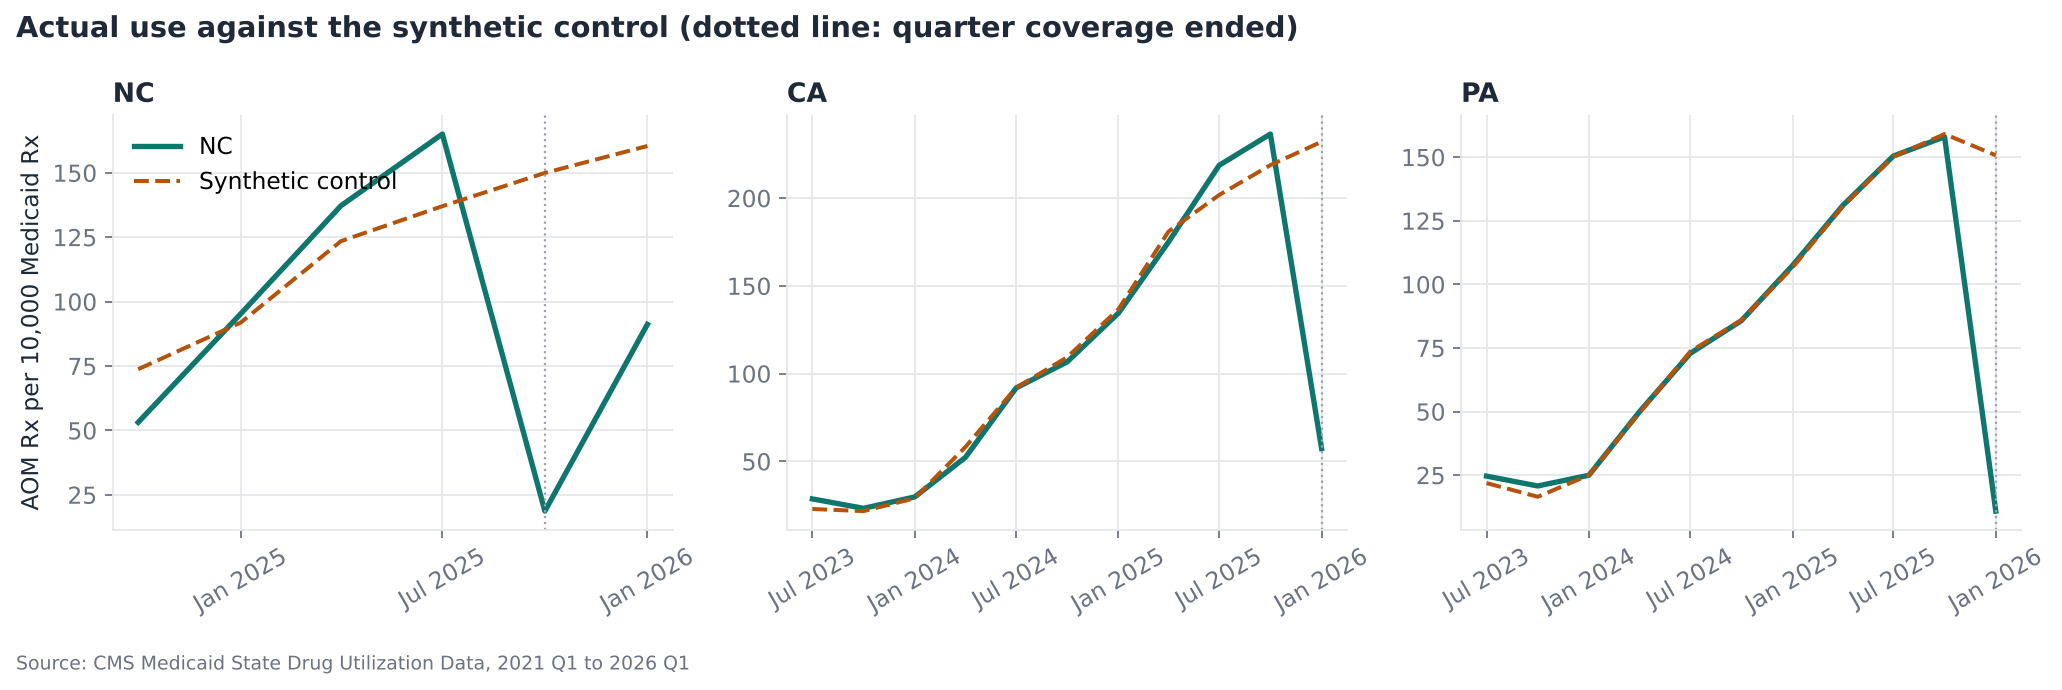

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
for ax, st in zip(axes, ["NC", "CA", "PA"]):
    idx = A.index[A.index >= (Q("2024Q4") if st == "NC" else Q("2023Q3"))]
    ax.plot(idx.to_timestamp(), A.loc[idx, st], color=style.ACCENT, lw=2.4, label=st)
    ax.plot(idx.to_timestamp(), cfs[st].loc[idx], color=style.ACCENT_2, lw=1.8, ls="--", label="Synthetic control")
    ax.axvline(Q(EVENTS[st]).to_timestamp(), color=style.NEUTRAL, lw=1, ls=":")
    ax.set_title(st, fontsize=12)
    ax.xaxis.set_major_locator(__import__("matplotlib").dates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(__import__("matplotlib").dates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("AOM Rx per 10,000 Medicaid Rx")
axes[0].legend(loc="upper left")
fig.suptitle("Actual use against the synthetic control (dotted line: quarter coverage ended)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=style.INK)
fig.tight_layout()
style.source(fig, SRC)
style.save(fig, FIG / "03_synthetic_controls.png")

## 3. After restarting, how much came back?

North Carolina restored coverage on 12 December 2025, so 2026 Q1 is its first
full quarter back. Compared with the synthetic control (what continuous
coverage would have produced), it recovered only part of its use.

In [7]:
q1 = Q("2026Q1")
recovered = float(A.loc[q1, "NC"] / cfs["NC"].loc[q1])
print(f"NC 2026 Q1: {A.loc[q1, 'NC']:.0f} per 10k against a counterfactual of {cfs['NC'].loc[q1]:.0f}: "
      f"{recovered:.0%} recovered in the first full quarter")

NC 2026 Q1: 91 per 10k against a counterfactual of 160: 57% recovered in the first full quarter


Restarting is not the same as never stopping. Patients who stopped had to get
a new prior authorisation, and some will have re-started at the lowest dose,
changed plans or given up. For a manufacturer, a coverage gap of ten weeks
left more than 40% of expected volume missing in the first full quarter
*after* coverage returned.

## 4. Did covering obesity drugs change diabetes GLP-1 use?

One worry is substitution: with no obesity coverage, patients might be steered
to diabetes-labelled versions (Ozempic, Mounjaro), and covering Wegovy might
reduce that. An event study tests it: a regression of the diabetes GLP-1 rate
on state and quarter fixed effects plus indicators for each quarter relative
to the start of NC's coverage. Standard errors are clustered by state.

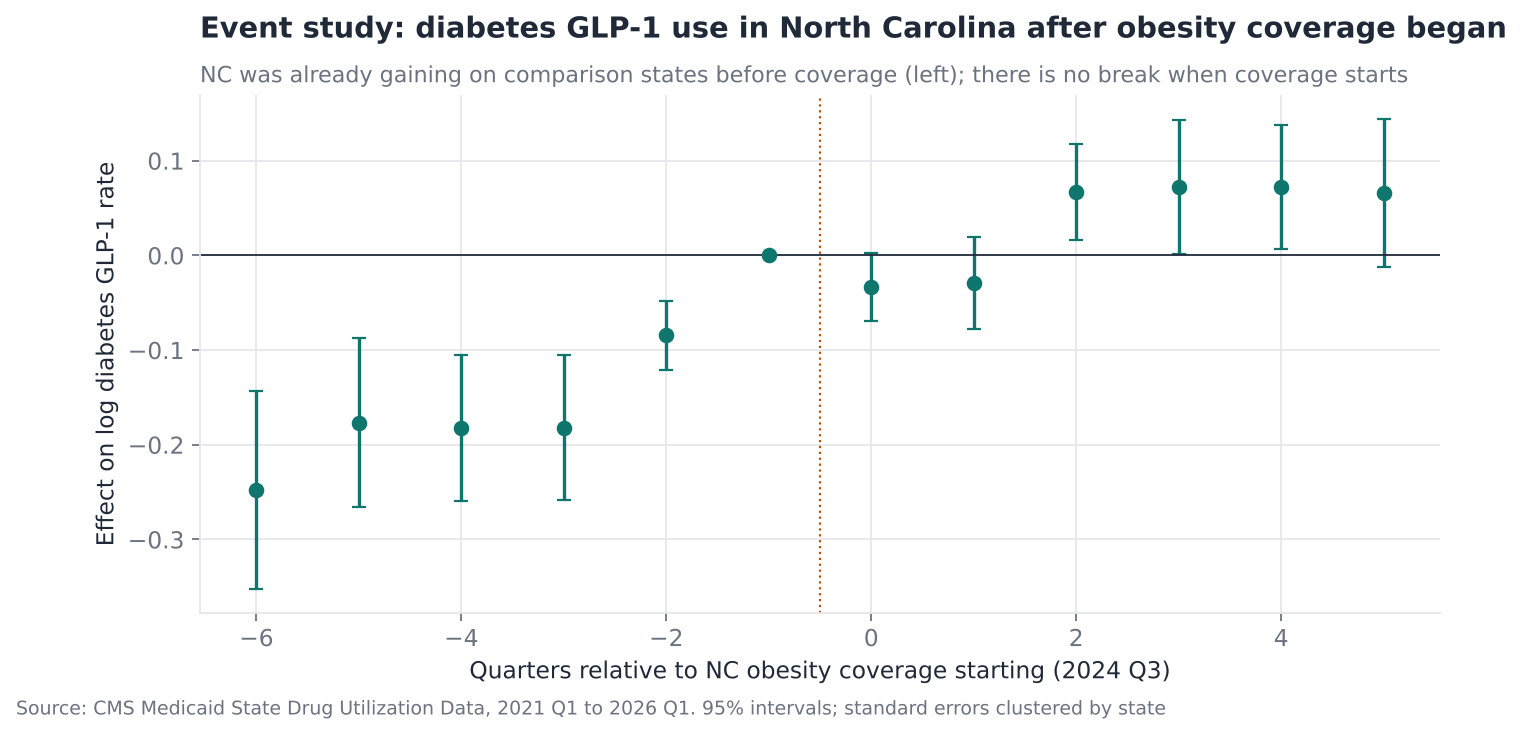

break_after_coverage         -0.018
ci_low                       -0.059
ci_high                       0.024
nc_extra_trend_per_quarter    0.033
dtype: float64

In [8]:
es = p[p["state"].isin(DONORS + ["NC"])].copy()
es["t"] = (es["period"] - Q("2024Q3")).apply(lambda x: x.n)
es["nc"] = (es["state"] == "NC").astype(int)
es["ln_dm"] = np.log(es["dm"].clip(lower=0.5))
es["quarter_label"] = es["period"].astype(str)
for k in range(-6, 6):
    if k != -1:
        es[f"e{k + 6}"] = ((es["t"] == k) & (es["nc"] == 1)).astype(int)
es = es[es["t"].between(-6, 5)]
terms = " + ".join(f"e{k + 6}" for k in range(-6, 6) if k != -1)
m = smf.ols(f"ln_dm ~ {terms} + C(state) + C(quarter_label)", data=es).fit(cov_type="cluster", cov_kwds={"groups": es["state"]})
coef = pd.DataFrame({"k": [k for k in range(-6, 6) if k != -1],
                     "coef": [m.params[f"e{k + 6}"] for k in range(-6, 6) if k != -1],
                     "se": [m.bse[f"e{k + 6}"] for k in range(-6, 6) if k != -1]})
coef = pd.concat([coef, pd.DataFrame({"k": [-1], "coef": [0.0], "se": [0.0]})]).sort_values("k")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.errorbar(coef["k"], coef["coef"], yerr=1.96 * coef["se"], fmt="o", color=style.ACCENT, capsize=3)
ax.axhline(0, color=style.INK, lw=0.8)
ax.axvline(-0.5, color=style.ACCENT_2, ls=":", lw=1)
ax.set_xlabel("Quarters relative to NC obesity coverage starting (2024 Q3)")
ax.set_ylabel("Effect on log diabetes GLP-1 rate")
ax.set_title("Event study: diabetes GLP-1 use in North Carolina after obesity coverage began")
style.subtitle(ax, "NC was already gaining on comparison states before coverage (left); there is no break when coverage starts")
style.source(fig, SRC + ". 95% intervals; standard errors clustered by state")
style.save(fig, FIG / "04_event_study_spillover.png")

# Allow NC its own linear pre-trend, then test for a break after coverage starts.
es["nc_trend"] = es["nc"] * es["t"]
es["nc_post"] = es["nc"] * (es["t"] >= 0)
m2 = smf.ols("ln_dm ~ nc_trend + nc_post + C(state) + C(quarter_label)", data=es).fit(cov_type="cluster", cov_kwds={"groups": es["state"]})
spill = {"break_after_coverage": float(m2.params["nc_post"]), "ci_low": float(m2.conf_int().loc["nc_post", 0]),
         "ci_high": float(m2.conf_int().loc["nc_post", 1]), "nc_extra_trend_per_quarter": float(m2.params["nc_trend"])}
pd.Series(spill).round(3)

The event study shows North Carolina's diabetes GLP-1 rate was already rising
faster than in comparison states before obesity coverage (the negative
estimates on the left mean NC started lower and caught up). That breaks the
"parallel trends" assumption a plain DiD relies on, so the second model gives
NC its own trend and asks only whether anything changed *at* the start of
coverage. The break estimate is close to zero, and its interval includes
zero. There is no evidence that covering Wegovy and Zepbound pulled patients
away from diabetes-labelled GLP-1s, or that diabetes products had been
absorbing obesity demand.

## 5. Designing a commercial pilot with real noise

Now the planning question. Suppose a brand team will run a programme in some
states for four quarters and measure diabetes GLP-1 prescriptions per 10,000
Medicaid prescriptions (the same KPI as above, standing in for brand demand).

**How the power analysis works.** Use real history in which nothing was
tested: pick random "test" states, add a known lift to their post-period, and
check whether each analysis method detects it. Repeating this 400 times per
setting gives **power**, the chance of detecting a real effect, and the
**minimum detectable effect (MDE)**, the smallest lift detected 80% of the
time. Because the noise is real state-to-state variation, the answer is
realistic rather than textbook.

Methods compared:
- **Post-only:** test vs control average after the start. What a dashboard shows.
- **DiD:** change in test minus change in control.
- **DiD + pre-period adjustment:** regression on each state's own pre-period
  level and trend (the idea behind CUPED, a standard variance-reduction method
  in online experiments).

In [9]:
pool = [s for s in D.columns if s not in {"XX", "PR", "NC", "CA", "PA", "NH", "SC", "TN", "MO"} and D[s].min() > 5]
Dl = np.log(D.loc[Q("2022Q1"):Q("2025Q3"), pool])
PRE, POST = Dl.index[:-4], Dl.index[-4:]
rng = np.random.default_rng(7)


def estimate(test: list[str], lift: float):
    Y = Dl.copy()
    Y.loc[POST, test] += np.log1p(lift)
    ctrl = [s for s in pool if s not in test]
    post_only = Y.loc[POST, test].mean().mean() - Y.loc[POST, ctrl].mean().mean()
    chg = Y.loc[POST].mean() - Y.loc[PRE].mean()
    did = chg[test].mean() - chg[ctrl].mean()
    # Pre-period adjustment: regress each state's post change on its own pre-period trend
    slope = Y.loc[PRE].apply(lambda s: np.polyfit(np.arange(len(s)), s.to_numpy(), 1)[0])
    df_ = pd.DataFrame({"chg": chg, "slope": slope, "test": [1 if s in test else 0 for s in pool]})
    adj = smf.ols("chg ~ test + slope", data=df_).fit()
    return post_only, did, adj.params["test"], adj.bse["test"]


def power(n_test: int, lift: float, sims: int = 400):
    hits = {"Post-only": [], "DiD": [], "DiD + pre-period adjustment": []}
    null = {"Post-only": [], "DiD": [], "DiD + pre-period adjustment": []}
    for _ in range(sims):
        test = list(rng.choice(pool, n_test, replace=False))
        e1 = estimate(test, lift)
        e0 = estimate(test, 0.0)
        for name, i in [("Post-only", 0), ("DiD", 1), ("DiD + pre-period adjustment", 2)]:
            hits[name].append(e1[i])
            null[name].append(e0[i])
    out = {}
    for name in hits:
        thr = np.percentile(np.abs(null[name]), 95)  # 5% false-positive rate, from the no-effect runs
        out[name] = float(np.mean(np.array(hits[name]) > thr))
    return out


grid = []
for n_test in [4, 8, 12, 16]:
    for lift in [0.02, 0.05, 0.10, 0.15, 0.20, 0.30]:
        for name, pw in power(n_test, lift).items():
            grid.append({"test states": n_test, "true lift": lift, "method": name, "power": pw})
grid = pd.DataFrame(grid)
grid.to_csv(TAB / "pilot_power_grid.csv", index=False)
grid.pivot_table(index=["method", "test states"], columns="true lift", values="power").round(2)

true lift                                0.02  0.05  0.10  0.15  0.20  0.30
method                      test states                                    
DiD                         4            0.02  0.10  0.38  0.64  0.86  0.97
                            8            0.05  0.16  0.57  0.84  0.98  1.00
                            12           0.09  0.20  0.69  0.93  0.99  1.00
                            16           0.09  0.26  0.83  0.97  1.00  1.00
DiD + pre-period adjustment 4            0.04  0.20  0.53  0.76  0.95  1.00
                            8            0.04  0.28  0.69  0.95  1.00  1.00
                            12           0.08  0.37  0.83  1.00  1.00  1.00
                            16           0.10  0.37  0.90  1.00  1.00  1.00
Post-only                   4            0.03  0.04  0.10  0.13  0.18  0.26
                            8            0.03  0.06  0.15  0.14  0.26  0.48
                            12           0.04  0.07  0.14  0.22  0.26  0.47
                            16           0.04  0.08  0.15  0.21  0.39  0.68

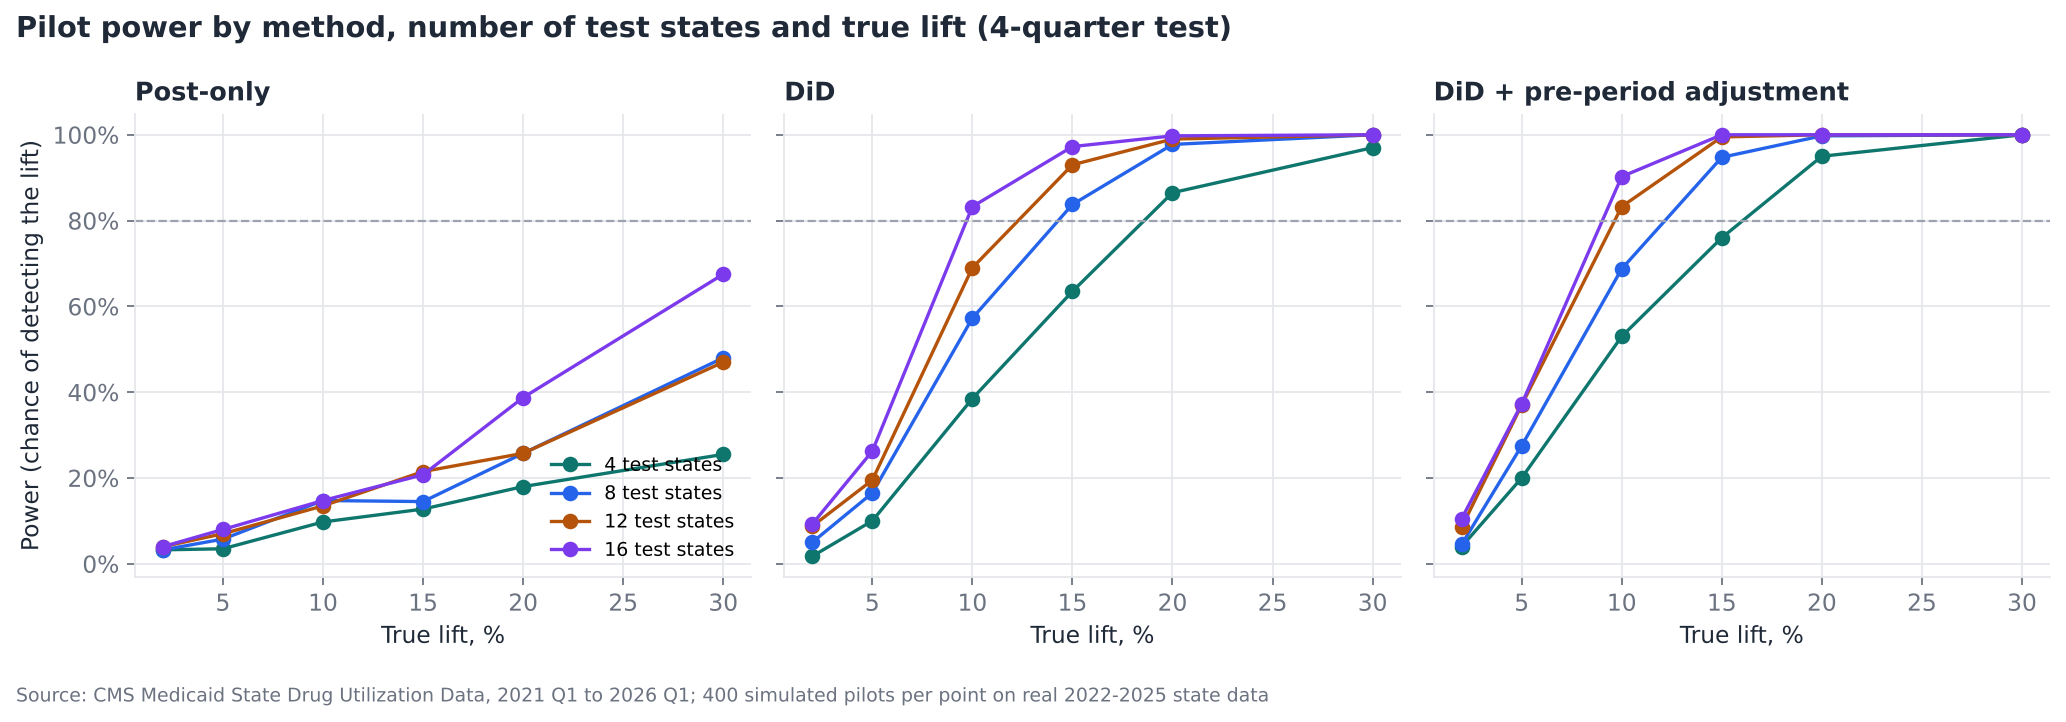

,method,4 states,8 states,12 states,16 states
0,Post-only,NaN,NaN,NaN,NaN
1,DiD,0.2,0.15,0.15,0.1
2,DiD + pre-period adjustment,0.2,0.15,0.10,0.1


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, name in zip(axes, ["Post-only", "DiD", "DiD + pre-period adjustment"]):
    for i, n_test in enumerate([4, 8, 12, 16]):
        g_ = grid[(grid["method"] == name) & (grid["test states"] == n_test)]
        ax.plot(g_["true lift"] * 100, g_["power"], marker="o", color=style.PALETTE[i], label=f"{n_test} test states")
    ax.axhline(0.8, color=style.NEUTRAL, ls="--", lw=1)
    ax.set_title(name, fontsize=11.5)
    ax.set_xlabel("True lift, %")
axes[0].set_ylabel("Power (chance of detecting the lift)")
style.pct(axes[0])
axes[0].legend(loc="lower right", fontsize=8.5)
fig.suptitle("Pilot power by method, number of test states and true lift (4-quarter test)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=style.INK)
fig.tight_layout()
style.source(fig, SRC + "; 400 simulated pilots per point on real 2022-2025 state data")
style.save(fig, FIG / "05_pilot_power.png")


def mde(name: str, n_test: int) -> float:
    g_ = grid[(grid["method"] == name) & (grid["test states"] == n_test)].sort_values("true lift")
    ok = g_[g_["power"] >= 0.8]
    return float(ok["true lift"].iloc[0]) if len(ok) else float("nan")


mde_tab = pd.DataFrame([{"method": nm, **{f"{n} states": mde(nm, n) for n in [4, 8, 12, 16]}}
                        for nm in ["Post-only", "DiD", "DiD + pre-period adjustment"]])
mde_tab

**Reading the result.** A post-only comparison needs a very large effect to be
seen, because states differ so much in level. Looking at the *change* (DiD)
removes those level differences and cuts the detectable effect several-fold,
and adjusting for each state's own pre-period trend helps further. The
practical rule: never read a pilot off a post-period dashboard; plan it as a
DiD with pre-period adjustment, and size it from a simulation like this one
before launch.

### Choosing matched controls for a named pilot

When the test states are fixed in advance (say, a regional pilot in the
Southeast), random assignment is not available. A synthetic control for the
test group, fitted on the pre-period, gives a matched comparison.

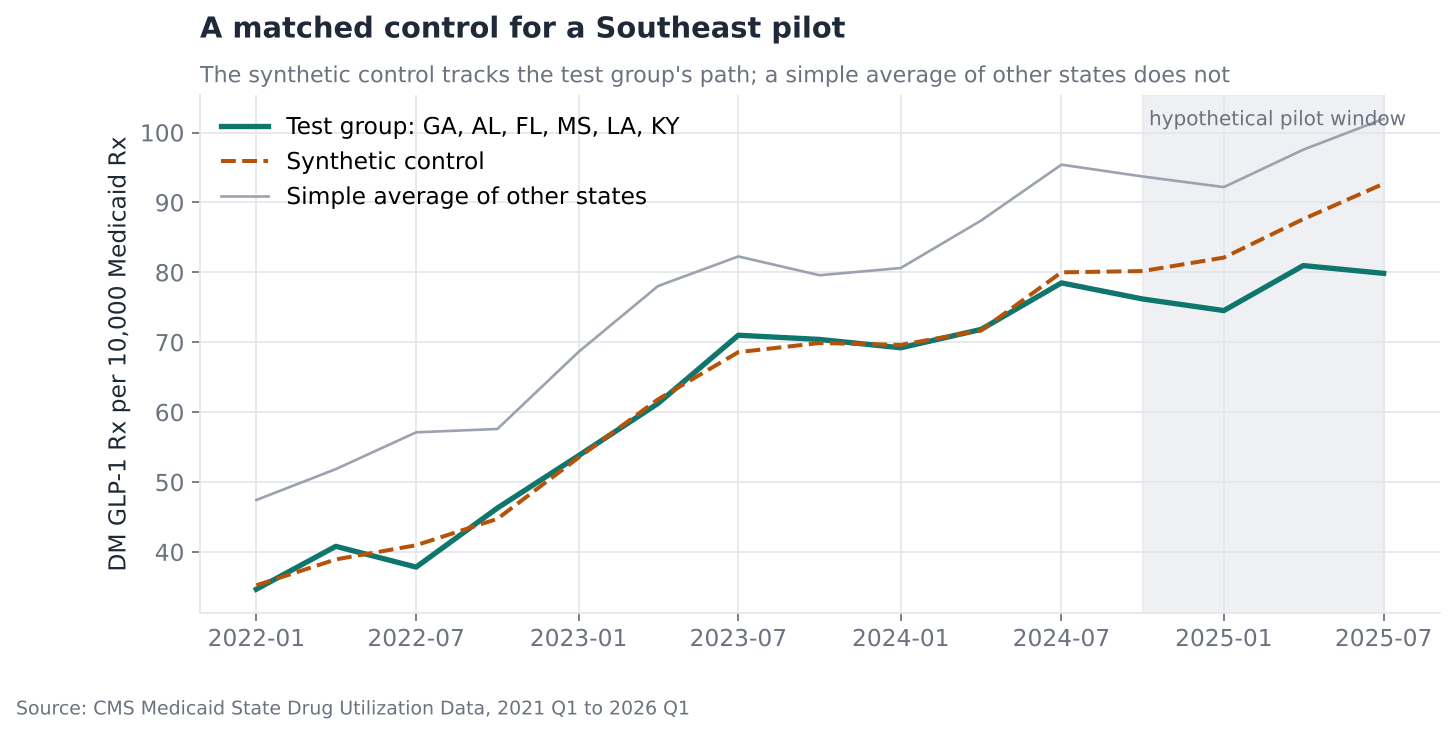

,synthetic control weight
SD,0.651
MI,0.195
AR,0.100
ID,0.051
ND,0.003
MA,0.000


In [11]:
test = ["GA", "AL", "FL", "MS", "LA", "KY"]
test = [s for s in test if s in pool]
ctrl = [s for s in pool if s not in test]
y_test = Dl.loc[:, test].mean(axis=1)
w = panel.synth_weights((y_test.loc[PRE] - y_test.loc[PRE].mean()).to_numpy(),
                        (Dl.loc[PRE, ctrl] - Dl.loc[PRE, ctrl].mean()).to_numpy())
y_syn = y_test.loc[PRE].mean() + (Dl[ctrl] - Dl.loc[PRE, ctrl].mean()) @ w
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(Dl.index.to_timestamp(), np.exp(y_test), color=style.ACCENT, lw=2.4, label="Test group: " + ", ".join(test))
ax.plot(Dl.index.to_timestamp(), np.exp(y_syn), color=style.ACCENT_2, lw=1.8, ls="--", label="Synthetic control")
ax.plot(Dl.index.to_timestamp(), np.exp(Dl[ctrl].mean(axis=1)), color=style.NEUTRAL, lw=1.2, label="Simple average of other states")
ax.axvspan(POST[0].to_timestamp(), POST[-1].to_timestamp(), color=style.GRID, alpha=0.6, zorder=0)
ax.text(POST[0].to_timestamp(), ax.get_ylim()[1] * 0.98, " hypothetical pilot window", color=style.MUTED, fontsize=9, va="top")
ax.set_ylabel("DM GLP-1 Rx per 10,000 Medicaid Rx")
ax.set_title("A matched control for a Southeast pilot")
style.subtitle(ax, "The synthetic control tracks the test group's path; a simple average of other states does not")
ax.legend(loc="upper left")
style.source(fig, SRC)
style.save(fig, FIG / "06_matched_market.png")
pre_err = float(np.sqrt(np.mean((y_test.loc[PRE] - y_syn.loc[PRE]) ** 2)))
pd.Series(dict(zip(ctrl, w))).sort_values(ascending=False).head(6).round(3).rename("synthetic control weight").to_frame()

## 6. Summary

In [12]:
summary = {
    "nc_aom_rate_2025Q3": round(float(A.loc[Q("2025Q3"), "NC"]), 1),
    "nc_aom_rate_2025Q4": round(float(A.loc[Q("2025Q4"), "NC"]), 1),
    "nc_aom_reimbursed_covered_quarters_musd": round(spend_on / 1e6, 1),
    "removal_drop_vs_synthetic": dict(zip(removal["state"], removal["drop vs synthetic"].round(3))),
    "removal_drop_vs_did": dict(zip(removal["state"], removal["drop vs DiD"].round(3))),
    "removal_lost_rx_first_quarter": dict(zip(removal["state"], removal["lost prescriptions in quarter"].round(0))),
    "placebo_effect_range": [round(float(plac["effect"].min()), 3), round(float(plac["effect"].max()), 3)],
    "nc_recovered_share_2026Q1": round(recovered, 3),
    "spillover_break_after_coverage": {k: round(v, 3) for k, v in spill.items()},
    "mde_at_80pct_power": mde_tab.set_index("method").to_dict(orient="index"),
    "matched_market_pre_rmse_log": round(pre_err, 4),
}
pd.Series(summary).to_json(TAB / "summary.json", indent=1)
summary

{'nc_aom_rate_2025Q3': 165.1,
 'nc_aom_rate_2025Q4': 18.7,
 'nc_aom_reimbursed_covered_quarters_musd': 335.5,
 'removal_drop_vs_synthetic': {'NC': -0.875,
  'CA': -0.753,
  'PA': -0.928,
  'NH': -0.859},
 'removal_drop_vs_did': {'NC': -0.891,
  'CA': -0.744,
  'PA': -0.927,
  'NH': -0.846},
 'removal_lost_rx_first_quarter': {'NC': 72828.0,
  'CA': 386771.0,
  'PA': 74739.0,
  'NH': 3798.0},
 'placebo_effect_range': [-0.338, 0.149],
 'nc_recovered_share_2026Q1': 0.568,
 'spillover_break_after_coverage': {'break_after_coverage': -0.018,
  'ci_low': -0.059,
  'ci_high': 0.024,
  'nc_extra_trend_per_quarter': 0.033},
 'mde_at_80pct_power': {'Post-only': {'4 states': nan,
   '8 states': nan,
   '12 states': nan,
   '16 states': nan},
  'DiD': {'4 states': 0.2,
   '8 states': 0.15,
   '12 states': 0.15,
   '16 states': 0.1},
  'DiD + pre-period adjustment': {'4 states': 0.2,
   '8 states': 0.15,
   '12 states': 0.1,
   '16 states': 0.1}},
 'matched_market_pre_rmse_log': 0.0326}